# 04 - Product and category analysis
**Question:** which categories carry revenue, and which are losing momentum?

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette=["#7C5CFF", "#22D3EE", "#FFB547", "#34E5A1", "#FF5C8A"])
pd.set_option("display.width", 140)
from python.database_loader import Database, run_named_query
db = Database(read_only=True)
run_named_query(db, 'rev_category_pareto').head(10)

,category,revenue,share_pct,cumulative_share_pct
0,watches_gifts,358235.19,11.45,11.45
1,health_beauty,324190.64,10.36,21.81
2,bed_bath_table,275898.87,8.82,30.63
3,computers,269834.79,8.62,39.25
4,furniture_decor,191259.24,6.11,45.36
5,computers_accessories,184384.99,5.89,51.25
6,sports_leisure,181729.92,5.81,57.06
7,home_appliances,160009.88,5.11,62.17
8,cool_stuff,136230.80,4.35,66.53
9,housewares,128669.54,4.11,70.64


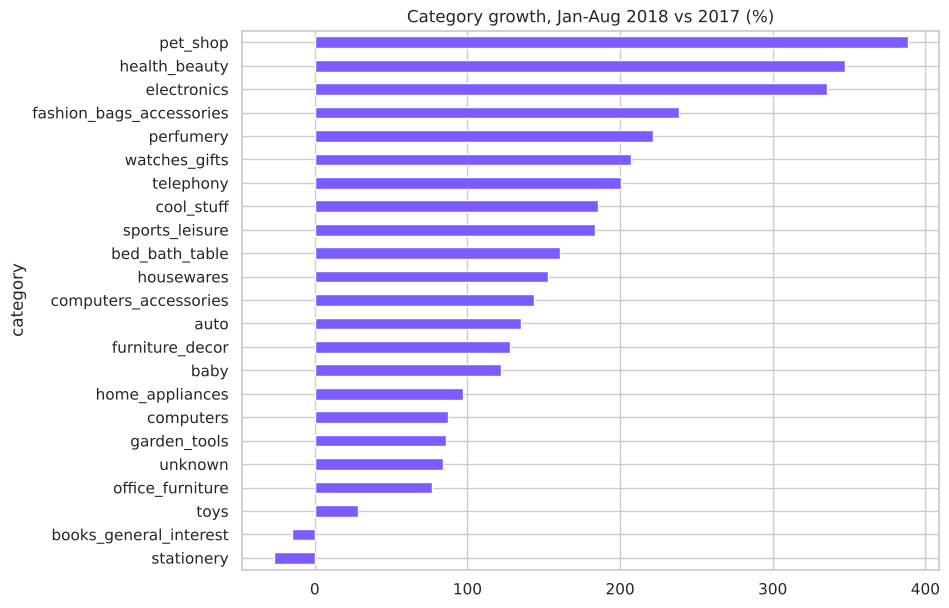

In [2]:
g = run_named_query(db, 'prd_category_growth'); g['growth_pct'] = g.growth_pct.astype(float)
g.sort_values('growth_pct').plot.barh(x='category', y='growth_pct', figsize=(9, 7), legend=False, title='Category growth, Jan-Aug 2018 vs 2017 (%)'); plt.show()

In [3]:
run_named_query(db, 'prd_declining_categories').head(8)

,category,previous_3m_revenue,last_3m_revenue,change_pct
0,books_general_interest,3082.56,1498.59,-51.4
1,stationery,2691.93,1973.23,-26.7
2,toys,11847.71,10852.79,-8.4
3,garden_tools,15964.14,15144.69,-5.1
4,office_furniture,18761.85,18629.38,-0.7
5,computers,53943.40,55168.22,2.3
6,bed_bath_table,56214.54,62575.66,11.3
7,sports_leisure,36171.64,40319.65,11.5


In [4]:
run_named_query(db, 'prd_revenue_concentration')

,products_selling,products_for_80pct_revenue,pct_of_catalogue
0,3226,866,26.8
